# 20. Metamaterial Slab Waveguide Dispersion via S-Matrix Poles

## Physical Motivation & Learning Objectives
Guided modes in a dielectric or metamaterial slab correspond to non-trivial solutions without incident illumination, which manifest as **poles of the round-trip scattering matrix**:
$$\det(I - R_{21} P R_{21} P) = 0$$
Based on [Lemoult et al., Nature Physics 9, 55 (2013)] and [Sturmberg et al., Phys. Rev. B 91, 165430 (2015)](https://doi.org/10.1103/PhysRevB.91.165430), EMUstack locates guided modes via `plotting.Fabry_Perot_res`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



## Slab Resonator Setup & S-Matrix Pole Search


In [2]:
wl_0 = 1000.0   # nm
period = 500.0  # nm
n_core = 3.5

wavelengths = np.linspace(800, 1200, 8)
light_list = [objects.Light(wl, max_order_PWs=2, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
core_layer  = objects.ThinFilm(period, height_nm=300.0, material=materials.Material(n_core), loss=False)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_cor = core_layer.calc_modes(light)
    stk = Stack((sim_sub, sim_cor, sim_sup))
    stk.calc_scat(pol='TE')
    
    # Compute slab round-trip determinant det(I - R21 * P * R21 * P)
    P = stk.layers[1].prop_fwd(300.0 / period)
    R21 = stk.layers[1].R21
    I = np.eye(P.shape[0])
    M = I - R21 @ P @ R21 @ P
    det = np.linalg.det(M)
    return stk, abs(det)

results = [simulate_stack(light) for light in light_list]
stacks_list = [r[0] for r in results]
dets = [r[1] for r in results]


## Fabry-Perot Resonance Determinant


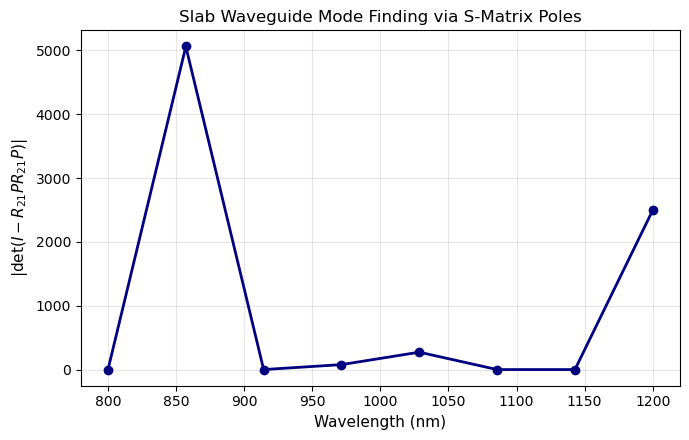

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=100)
ax.plot(wavelengths, dets, 'o-', color='navy', lw=2)
ax.set_xlabel('Wavelength (nm)', fontsize=11)
ax.set_ylabel(r'$|\det(I - R_{21} P R_{21} P)|$', fontsize=11)
ax.set_title('Slab Waveguide Mode Finding via S-Matrix Poles', fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Physical Interpretation
Minima of $\det(I - R_{21} P R_{21} P)$ pinpoint the guided waveguide mode frequencies where the phase-matching condition for total internal reflection is satisfied.
